# Support Vector Regression — Part 1: Theory and Geometric Intuition

**Goal of this notebook:** conceptual clarity. Every idea is introduced three times — once in words,
once in mathematics, and once as a picture you can manipulate with a slider.

### How to use it
* Run cells top to bottom. Each interactive cell defines a plain function first, then wraps it in a
  slider, so you can also call the function directly with your own numbers.
* In Google Colab the `ipywidgets` sliders and the Plotly 3-D plots work out of the box.
* Nothing here needs an internet connection or an external dataset.

### Road map

| § | Concept | What you will see |
|---|---------|-------------------|
| 1 | The SVR stance on regression | the $\varepsilon$-tube vs. the least-squares line |
| 2 | $\varepsilon$-insensitive loss | loss curves, slider on $\varepsilon$ |
| 3 | Flatness = $\tfrac12\lVert w\rVert^2$ | the objective split into its two competing halves |
| 4 | Primal problem, slack variables | annotated geometry of $\xi,\xi^\*$ |
| 5 | Lagrangian → dual | full derivation + a solver written from scratch |
| 6 | KKT conditions | which points become support vectors, and why |
| 7 | Sparsity | #SV as a function of $\varepsilon$ |
| 8 | The kernel trick | explicit feature lift in 3-D, Gram-matrix heat maps |
| 9 | $C$, $\varepsilon$, $\gamma$ | three-slider explorer |
| 10 | $\nu$-SVR | the two bounds $\nu$ controls |
| 11 | Why scaling is not optional | same data, two scalings |
| 12 | Complexity | measured fit time vs. $n$ |
| 13 | SVR's relatives | Ridge, KRR, GPR, and the representer theorem |
| 14 | Cheat sheet | summary table + common misconceptions |

In [1]:
# ----------------------------------------------------------------------
# Setup.  Run this first.
# ----------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.optimize import minimize

from sklearn.svm import SVR, NuSVR, LinearSVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics.pairwise import rbf_kernel, linear_kernel, polynomial_kernel, sigmoid_kernel
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
})

# A consistent colour language used throughout the notebook:
C_DATA   = "#444444"   # data points
C_FIT    = "#0072B2"   # the fitted function f(x)
C_TUBE   = "#56B4E9"   # the epsilon-tube
C_SV     = "#D55E00"   # support vectors (on the tube boundary)
C_BOUND  = "#CC79A7"   # bounded support vectors (outside the tube, alpha = C)
C_IN     = "#009E73"   # non-support vectors (strictly inside the tube)

# --- interaction helper: use sliders if ipywidgets is present, else fall back ---
try:
    from ipywidgets import interact, interactive_output, FloatSlider, IntSlider, Dropdown, Checkbox, VBox, HBox
    HAS_WIDGETS = True
except Exception:                                    # pragma: no cover
    HAS_WIDGETS = False
    print("ipywidgets not available -- interactive cells will render a single static view.")

def show(func, **controls):
    """interact(func, **controls) when widgets exist; otherwise call func at the slider defaults."""
    if HAS_WIDGETS:
        return interact(func, **controls)
    defaults = {k: (v.value if hasattr(v, "value") else v) for k, v in controls.items()}
    return func(**defaults)

# --- the toy dataset used in most of the theory figures ---
def make_wave(n=60, noise=0.18, seed=0, outliers=0):
    """1-D regression data: a smooth signal + Gaussian noise (+ optional gross outliers)."""
    rng = np.random.default_rng(seed)
    X = np.sort(rng.uniform(-3.0, 3.0, n)).reshape(-1, 1)
    y = np.sin(X).ravel() + 0.3 * X.ravel() + noise * rng.standard_normal(n)
    if outliers:
        idx = rng.choice(n, outliers, replace=False)
        y[idx] += rng.choice([-1, 1], outliers) * rng.uniform(1.5, 2.5, outliers)
    return X, y

X, y = make_wave()
X_grid = np.linspace(-3.2, 3.2, 400).reshape(-1, 1)
print("toy data:", X.shape, y.shape, "| widgets:", HAS_WIDGETS)

toy data: (60, 1) (60,) | widgets: True


---
## 1. What question is SVR actually asking?

Ordinary least squares asks: **"which function makes the sum of squared errors as small as
possible?"** Every single residual, however tiny, pushes the fit around, and one gross outlier can
pull the whole line because its residual is squared.

Support vector regression asks a different question, in two parts:

> **(a)** Can I find a function that keeps *almost all* the training points inside a tube of
> half-width $\varepsilon$ around it?
> **(b)** Among all such functions, which one is the **flattest**?

Three consequences follow immediately, and they are the entire personality of the method:

1. **A tolerance band.** Residuals smaller than $\varepsilon$ cost *nothing*. The model is
   deliberately blind to errors you have declared to be "measurement noise, not signal."
2. **Sparsity.** Points strictly inside the tube have zero influence on the solution. Delete them
   and refit — you get the identical function. Only the points on or outside the tube wall, the
   **support vectors**, define the model.
3. **Capacity control by flatness.** "Flattest" means smallest $\lVert w\rVert$. This is the same
   quantity that becomes the *margin* in support vector classification, and it is what keeps a very
   flexible kernel model from chasing noise.

The figure below contrasts the two stances on the same data.

In [2]:
def plot_stance(eps=0.5):
    """Least squares (every residual counts) vs. the SVR tube (small residuals are free)."""
    ols = LinearRegression().fit(X, y)
    svr = make_pipeline(StandardScaler(), SVR(kernel="linear", C=10.0, epsilon=eps)).fit(X, y)
    yg_ols, yg_svr = ols.predict(X_grid), svr.predict(X_grid)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)

    ax = axes[0]
    ax.scatter(X, y, s=28, c=C_DATA, zorder=3, label="data")
    ax.plot(X_grid, yg_ols, color=C_FIT, lw=2, label="least-squares line")
    ax.vlines(X.ravel(), y, ols.predict(X), color=C_SV, lw=1, alpha=0.7)
    ax.set_title("OLS: every residual is penalised ($r^2$)")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper left")

    ax = axes[1]
    resid = y - svr.predict(X)
    inside = np.abs(resid) <= eps + 1e-9
    ax.fill_between(X_grid.ravel(), yg_svr - eps, yg_svr + eps,
                    color=C_TUBE, alpha=0.30, label=rf"$\varepsilon$-tube ($\varepsilon$={eps:g})")
    ax.plot(X_grid, yg_svr, color=C_FIT, lw=2, label="SVR fit $f(x)$")
    ax.scatter(X[inside], y[inside], s=28, c=C_IN, zorder=3, label="free (cost 0)")
    ax.scatter(X[~inside], y[~inside], s=38, c=C_SV, zorder=3, label="penalised")
    for xi, yi, ri in zip(X.ravel()[~inside], y[~inside], resid[~inside]):
        ax.vlines(xi, yi, yi - np.sign(ri) * (abs(ri) - eps), color=C_SV, lw=1.2)
    ax.set_title(f"SVR: only the excess beyond $\\varepsilon$ is penalised "
                 f"({(~inside).sum()}/{len(y)} points)")
    ax.set_xlabel("x"); ax.legend(loc="upper left")

    fig.tight_layout()
    plt.show()

show(plot_stance, eps=FloatSlider(value=0.5, min=0.01, max=1.5, step=0.01,
                                  description="ε") if HAS_WIDGETS else 0.5)

interactive(children=(FloatSlider(value=0.5, description='ε', max=1.5, min=0.01, step=0.01), Output()), _dom_c…

<function __main__.plot_stance(eps=0.5)>

---
## 2. The $\varepsilon$-insensitive loss

Everything in §1(a) is encoded in one loss function. For a prediction $\hat y = f(x)$ and a target
$y$, Vapnik's **$\varepsilon$-insensitive loss** is

$$
L_\varepsilon(y,\hat y)\;=\;\bigl(|y-\hat y|-\varepsilon\bigr)_+ \;=\;
\begin{cases}
0, & |y-\hat y|\le \varepsilon,\\[4pt]
|y-\hat y|-\varepsilon, & \text{otherwise,}
\end{cases}
$$

where $(z)_+=\max(0,z)$. Compare it with its relatives:

| Loss | Formula | Shape | Behaviour |
|------|---------|-------|-----------|
| Squared | $r^2$ | parabola | smooth, **no** dead zone, outliers dominate ($\propto r^2$) |
| Absolute (L1) | $\lvert r\rvert$ | V | robust, **no** dead zone, no sparsity |
| Huber | quadratic then linear | smooth V | robust, **no** dead zone |
| $\varepsilon$-insensitive | $(\lvert r\rvert-\varepsilon)_+$ | flat-bottomed V | robust **and** has a dead zone ⇒ sparsity |

Two properties matter, and they are independent of each other:

* **The flat bottom ($|r|\le\varepsilon$) buys sparsity.** The derivative is exactly zero there, so
  those points contribute nothing to the gradient of the objective and drop out of the solution.
  This is what no other common regression loss gives you.
* **The linear arms buy robustness.** Beyond the tube the penalty grows like $|r|$, not $r^2$, so a
  wild point pulls with bounded force. (In the dual this shows up as a hard cap, $\alpha_i\le C$.)

Setting $\varepsilon = 0$ collapses the loss to plain L1 — SVR then behaves like a kernelised
least-absolute-deviations fit and sparsity disappears. **$\varepsilon$ is the sparsity knob.**

In [3]:
def plot_losses(eps=0.5, huber_delta=1.0):
    r = np.linspace(-3, 3, 601)
    sq    = r**2
    absol = np.abs(r)
    hub   = np.where(np.abs(r) <= huber_delta,
                     0.5*r**2, huber_delta*(np.abs(r) - 0.5*huber_delta))
    einse = np.maximum(0.0, np.abs(r) - eps)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))

    ax = axes[0]
    ax.plot(r, sq,    lw=2, label=r"squared  $r^2$")
    ax.plot(r, absol, lw=2, label=r"absolute  $|r|$")
    ax.plot(r, hub,   lw=2, label=rf"Huber  $\delta$={huber_delta:g}")
    ax.plot(r, einse, lw=2.6, color=C_FIT, label=rf"$\varepsilon$-insensitive  $\varepsilon$={eps:g}")
    ax.axvspan(-eps, eps, color=C_TUBE, alpha=0.25)
    ax.text(0, 0.35, "dead zone\n(cost 0)", ha="center", va="bottom", fontsize=9, color="#2a6f97")
    ax.set_xlabel("residual  $r = y - f(x)$"); ax.set_ylabel("loss")
    ax.set_title("Loss functions"); ax.set_ylim(-0.15, 3.2); ax.legend(fontsize=9)

    # The derivative is what the optimiser actually feels.
    ax = axes[1]
    ax.plot(r, 2*r, lw=2, label=r"$d(r^2)/dr$")
    ax.plot(r, np.sign(r), lw=2, label=r"$d|r|/dr$")
    ax.plot(r, np.sign(r)*(np.abs(r) > eps), lw=2.6, color=C_FIT,
            label=r"$dL_\varepsilon/dr$")
    ax.axvspan(-eps, eps, color=C_TUBE, alpha=0.25)
    ax.set_xlabel("residual  $r$"); ax.set_ylabel("influence  $dL/dr$")
    ax.set_title("Influence: zero inside the tube, bounded outside")
    ax.set_ylim(-3, 3); ax.legend(fontsize=9)

    fig.tight_layout()
    plt.show()

show(plot_losses,
     eps=FloatSlider(value=0.5, min=0.0, max=2.0, step=0.05, description="ε") if HAS_WIDGETS else 0.5,
     huber_delta=FloatSlider(value=1.0, min=0.2, max=2.5, step=0.1, description="δ (Huber)") if HAS_WIDGETS else 1.0)

interactive(children=(FloatSlider(value=0.5, description='ε', max=2.0, step=0.05), FloatSlider(value=1.0, desc…

<function __main__.plot_losses(eps=0.5, huber_delta=1.0)>

---
## 3. "Flattest" means smallest $\lVert w\rVert$ — the other half of the objective

Part (b) of the SVR question needs a definition of *flat*. For a linear model
$f(x)=\langle w,x\rangle+b$, flatness means a small slope vector, measured as
$\tfrac12\lVert w\rVert^2 = \tfrac12\sum_j w_j^2$.

Why should flatness be the thing we want?

* **Stability.** $|f(x)-f(x')|\le\lVert w\rVert\,\lVert x-x'\rVert$. Small $\lVert w\rVert$ means the
  prediction cannot swing wildly when the input moves a little — a Lipschitz bound on the model.
* **It is exactly ridge regularisation.** $\tfrac12\lVert w\rVert^2$ is the same $\ell_2$ penalty
  ridge regression uses; SVR simply pairs it with a different loss.
* **It is the margin, re-used.** In SV *classification* you maximise the margin $2/\lVert w\rVert$.
  In SV *regression* you minimise $\lVert w\rVert$ subject to staying in the tube: the same geometry,
  rotated into the output direction.
* **Statistical-learning motivation.** Vapnik's bounds control capacity through $\lVert w\rVert$,
  not through the number of parameters — which is why the method survives the infinite-dimensional
  feature spaces of §8.

So the complete SVR objective is a **tug of war**:

$$
\underbrace{\tfrac12\lVert w\rVert^{2}}_{\text{flatness / capacity}}
\;+\;
C\underbrace{\sum_{i=1}^{n}\bigl(|y_i-f(x_i)|-\varepsilon\bigr)_+}_{\text{tube violations}}
\;\longrightarrow\;\min .
$$

$C>0$ sets the exchange rate between the two. Slide $w$ below and watch the two terms trade off; the
minimum of the orange curve is what the optimiser is looking for.

In [4]:
def plot_flatness(w=0.8, eps=0.4, C=1.0):
    """Fit b optimally for each slope w, then show the two halves of the objective."""
    xr, yr = X.ravel(), y

    def obj_parts(w_):
        b_ = np.median(yr - w_ * xr)                    # near-optimal b for the L1-type loss
        r  = yr - (w_ * xr + b_)
        return 0.5 * w_**2, C * np.maximum(0, np.abs(r) - eps).sum(), b_

    ws = np.linspace(-0.2, 1.8, 241)
    flat, viol = np.zeros_like(ws), np.zeros_like(ws)
    for k, w_ in enumerate(ws):
        flat[k], viol[k], _ = obj_parts(w_)
    total = flat + viol
    w_star = ws[np.argmin(total)]

    f_now, v_now, b_now = obj_parts(w)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

    ax = axes[0]
    yg = w * X_grid.ravel() + b_now
    ax.fill_between(X_grid.ravel(), yg - eps, yg + eps, color=C_TUBE, alpha=0.30)
    ax.plot(X_grid.ravel(), yg, color=C_FIT, lw=2)
    r = yr - (w * xr + b_now)
    ins = np.abs(r) <= eps
    ax.scatter(xr[ins],  yr[ins],  s=26, c=C_IN,  zorder=3)
    ax.scatter(xr[~ins], yr[~ins], s=34, c=C_SV,  zorder=3)
    ax.set_title(f"slope w = {w:.2f}   ·   {(~ins).sum()} points violate the tube")
    ax.set_xlabel("x"); ax.set_ylabel("y")

    ax = axes[1]
    ax.plot(ws, flat,  lw=2, label=r"$\frac{1}{2}\|w\|^2$  (flatness)")
    ax.plot(ws, viol,  lw=2, label=r"$C\sum(|r|-\varepsilon)_+$  (violations)")
    ax.plot(ws, total, lw=2.6, color="#E69F00", label="total objective")
    ax.axvline(w, color=C_DATA, ls=":", lw=1.5)
    ax.axvline(w_star, color="#E69F00", ls="--", lw=1.5)
    ax.scatter([w], [f_now + v_now], s=55, color=C_DATA, zorder=4)
    ax.set_xlabel("slope  $w$"); ax.set_ylabel("objective value")
    ax.set_title(f"optimum at w* ≈ {w_star:.2f}   (C = {C:g})")
    ax.legend(fontsize=9)

    fig.tight_layout()
    plt.show()
    print(f"at w = {w:.2f}:  flatness = {f_now:.3f}   violations = {v_now:.3f}   total = {f_now+v_now:.3f}")

show(plot_flatness,
     w=FloatSlider(value=0.8, min=-0.2, max=1.8, step=0.02, description="w") if HAS_WIDGETS else 0.8,
     eps=FloatSlider(value=0.4, min=0.05, max=1.5, step=0.05, description="ε") if HAS_WIDGETS else 0.4,
     C=FloatSlider(value=1.0, min=0.05, max=20.0, step=0.05, description="C") if HAS_WIDGETS else 1.0)

interactive(children=(FloatSlider(value=0.8, description='w', max=1.8, min=-0.2, step=0.02), FloatSlider(value…

<function __main__.plot_flatness(w=0.8, eps=0.4, C=1.0)>

---
## 4. The primal problem and the slack variables

Demanding that *every* point lie inside the tube is usually infeasible (and if it is feasible, it is
a recipe for overfitting). So we allow violations but charge for them, with one slack variable per
side:

$$
\boxed{
\begin{aligned}
\min_{w,\,b,\,\xi,\,\xi^{*}}\quad & \tfrac12\lVert w\rVert^{2}
      \;+\; C\sum_{i=1}^{n}\bigl(\xi_i+\xi_i^{*}\bigr)\\[4pt]
\text{s.t.}\quad & y_i-\langle w,x_i\rangle-b \;\le\; \varepsilon+\xi_i
      &&\text{(point sits \textbf{above} the tube)}\\
 & \langle w,x_i\rangle+b-y_i \;\le\; \varepsilon+\xi_i^{*}
      &&\text{(point sits \textbf{below} the tube)}\\
 & \xi_i,\;\xi_i^{*}\;\ge\;0,\qquad i=1,\dots,n .
\end{aligned}}
$$

Read it slowly:

* $\xi_i$ is how far point $i$ pokes out of the **top** of the tube; $\xi_i^*$ how far out of the
  **bottom**. A point can only violate one side, so $\xi_i\,\xi_i^{*}=0$ always.
* If the point is inside the tube, both constraints hold with $\xi_i=\xi_i^{*}=0$ and it costs nothing.
* $\sum(\xi_i+\xi_i^*)$ is precisely $\sum L_\varepsilon(y_i,f(x_i))$ — the slack formulation and the
  loss formulation of §2–3 are the same problem, written twice.

**This is a convex quadratic program**: a positive-definite quadratic objective under linear
constraints. Hence there is a *unique* global minimum and no local-optimum lottery — a genuine
structural advantage over neural networks.

**Degrees of freedom:** $d+1+2n$ variables in the primal. Note the $2n$ — this is why we move to the
dual, where the problem is in $2n$ variables but every $x_i$ appears only inside an inner product.

**Role of $C$ at the extremes**
* $C\to\infty$: violations become unaffordable — hard tube, maximal flexibility, overfitting.
  (With an RBF kernel and small $\varepsilon$, the model interpolates the noise.)
* $C\to 0$: flatness dominates — $w\to 0$ and $f(x)\to\text{const}$, i.e. a flat line near the median
  of $y$. Underfitting.

In [5]:
def plot_slack(eps=0.45, C=3.0):
    """Annotated geometry of xi and xi*: the distance from the tube wall, not from the line."""
    m = make_pipeline(StandardScaler(), SVR(kernel="linear", C=C, epsilon=eps)).fit(X, y)
    f_tr, yg = m.predict(X), m.predict(X_grid)
    r = y - f_tr
    above, below = r > eps, r < -eps
    xi      = np.maximum(0.0, r - eps)      # slack on the upper side
    xi_star = np.maximum(0.0, -r - eps)     # slack on the lower side

    fig, ax = plt.subplots(figsize=(9.5, 5.2))
    ax.fill_between(X_grid.ravel(), yg - eps, yg + eps, color=C_TUBE, alpha=0.28, zorder=0)
    ax.plot(X_grid, yg, color=C_FIT, lw=2.2, zorder=2, label=r"$f(x)=\langle w,x\rangle+b$")
    ax.plot(X_grid, yg + eps, color=C_FIT, lw=1, ls="--", zorder=2)
    ax.plot(X_grid, yg - eps, color=C_FIT, lw=1, ls="--", zorder=2)

    inside = ~(above | below)
    ax.scatter(X[inside], y[inside], s=30, c=C_IN, zorder=3, label=r"inside: $\xi=\xi^*=0$")
    ax.scatter(X[above],  y[above],  s=46, c=C_SV, zorder=3, label=r"above: $\xi>0$")
    ax.scatter(X[below],  y[below],  s=46, c=C_BOUND, marker="s", zorder=3, label=r"below: $\xi^*>0$")

    for xi_pt, y_pt, f_pt, s in zip(X.ravel()[above], y[above], f_tr[above], xi[above]):
        ax.annotate("", xy=(xi_pt, y_pt), xytext=(xi_pt, f_pt + eps),
                    arrowprops=dict(arrowstyle="<->", color=C_SV, lw=1.3))
    for xi_pt, y_pt, f_pt, s in zip(X.ravel()[below], y[below], f_tr[below], xi_star[below]):
        ax.annotate("", xy=(xi_pt, y_pt), xytext=(xi_pt, f_pt - eps),
                    arrowprops=dict(arrowstyle="<->", color=C_BOUND, lw=1.3))

    if above.any():
        k = np.argmax(xi)
        ax.annotate(r"$\xi_i$", xy=(X.ravel()[k], 0.5*(y[k] + f_tr[k] + eps)),
                    xytext=(8, 0), textcoords="offset points", color=C_SV, fontsize=14)
    if below.any():
        k = np.argmax(xi_star)
        ax.annotate(r"$\xi_i^{*}$", xy=(X.ravel()[k], 0.5*(y[k] + f_tr[k] - eps)),
                    xytext=(8, 0), textcoords="offset points", color=C_BOUND, fontsize=14)

    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_title(rf"Slack = distance past the tube wall   ($\varepsilon$={eps:g}, C={C:g})   "
                 rf"$\sum(\xi+\xi^*)$ = {xi.sum()+xi_star.sum():.2f}")
    ax.legend(loc="upper left", fontsize=9)
    fig.tight_layout(); plt.show()

show(plot_slack,
     eps=FloatSlider(value=0.45, min=0.05, max=1.5, step=0.05, description="ε") if HAS_WIDGETS else 0.45,
     C=FloatSlider(value=3.0, min=0.05, max=50.0, step=0.05, description="C") if HAS_WIDGETS else 3.0)

interactive(children=(FloatSlider(value=0.45, description='ε', max=1.5, min=0.05, step=0.05), FloatSlider(valu…

<function __main__.plot_slack(eps=0.45, C=3.0)>

---
## 5. From primal to dual — the derivation in full

The dual is not a formality. It is the step that (i) removes the explicit $w$, (ii) makes every data
point enter only through **inner products**, which is what later lets us swap in a kernel, and
(iii) exposes the sparsity.

### 5.1 Build the Lagrangian

Attach a non-negative multiplier to each of the $4n$ constraints:
$\alpha_i\ge0$ (upper), $\alpha_i^{*}\ge0$ (lower), $\eta_i,\eta_i^{*}\ge0$ (the slack
non-negativities):

$$
\begin{aligned}
\mathcal{L} \;=\;& \tfrac12\lVert w\rVert^{2} + C\sum_i(\xi_i+\xi_i^{*})
 \;-\;\sum_i(\eta_i\xi_i+\eta_i^{*}\xi_i^{*})\\
 &-\sum_i \alpha_i\bigl(\varepsilon+\xi_i-y_i+\langle w,x_i\rangle+b\bigr)\\
 &-\sum_i \alpha_i^{*}\bigl(\varepsilon+\xi_i^{*}+y_i-\langle w,x_i\rangle-b\bigr).
\end{aligned}
$$

### 5.2 Stationarity: differentiate and set to zero

$$
\begin{aligned}
\frac{\partial\mathcal{L}}{\partial b}&=\sum_i(\alpha_i^{*}-\alpha_i)=0
 &&\Longrightarrow\quad \sum_i(\alpha_i-\alpha_i^{*})=0,\\[4pt]
\frac{\partial\mathcal{L}}{\partial w}&=w-\sum_i(\alpha_i-\alpha_i^{*})x_i=0
 &&\Longrightarrow\quad \boxed{\;w=\sum_i(\alpha_i-\alpha_i^{*})\,x_i\;}\\[4pt]
\frac{\partial\mathcal{L}}{\partial \xi_i^{(*)}}&=C-\alpha_i^{(*)}-\eta_i^{(*)}=0
 &&\Longrightarrow\quad \boxed{\;0\le\alpha_i^{(*)}\le C\;}
\end{aligned}
$$

Two results of enormous consequence are already visible:

* **$w$ is a linear combination of the training inputs.** This is the representer theorem appearing
  concretely: the solution lives in the span of the data, no matter how large the ambient space.
* **$C$ is a hard ceiling on each multiplier.** No single point, however outlying, can pull with more
  force than $C$. That *is* SVR's robustness, in one inequality.

### 5.3 Substitute back — the dual problem

$$
\boxed{
\begin{aligned}
\max_{\alpha,\alpha^{*}}\quad
&-\tfrac12\sum_{i,j}(\alpha_i-\alpha_i^{*})(\alpha_j-\alpha_j^{*})\langle x_i,x_j\rangle
 \;-\;\varepsilon\sum_i(\alpha_i+\alpha_i^{*})
 \;+\;\sum_i y_i(\alpha_i-\alpha_i^{*})\\[4pt]
\text{s.t.}\quad & \sum_i(\alpha_i-\alpha_i^{*})=0,
\qquad \alpha_i,\alpha_i^{*}\in[0,C].
\end{aligned}}
$$

Three terms, three meanings: the first is the flatness penalty rewritten; the second is the price
$\varepsilon$ charges for *using* a point at all (it pushes multipliers toward zero → sparsity); the
third rewards explaining the targets.

### 5.4 The prediction function

Writing $\beta_i:=\alpha_i-\alpha_i^{*}$ (sklearn stores exactly this in `dual_coef_`):

$$
f(x)=\sum_{i=1}^{n}\beta_i\,\langle x_i,x\rangle+b
\qquad\xrightarrow[\text{§8}]{\text{kernel}}\qquad
f(x)=\sum_{i=1}^{n}\beta_i\,k(x_i,x)+b .
$$

**The training inputs never appear alone — only inside an inner product.** Remember this sentence;
§8 is built on it.

### 5.5 Recovering $b$

$b$ is not in the dual, so it is recovered afterwards from any **unbounded** support vector
($0<\alpha_i<C$), which by complementary slackness sits exactly on a tube wall:

$$
b = y_i-\sum_j\beta_j k(x_j,x_i)-\varepsilon \;\;(\text{if }0<\alpha_i<C),\qquad
b = y_i-\sum_j\beta_j k(x_j,x_i)+\varepsilon \;\;(\text{if }0<\alpha_i^{*}<C).
$$

In practice one averages over all such points for numerical stability.

The next cell solves this dual directly with a general-purpose QP solver and checks it against
`sklearn.svm.SVR`. If the two agree, the derivation above is correct — not merely plausible.

In [6]:
def svr_dual_from_scratch(K, y, C, eps, tol=1e-6):
    """Solve the SVR dual directly.  Variables z = [alpha (n), alpha* (n)].

    minimise  1/2 b'Kb + eps*sum(alpha+alpha*) - y'b      with b = alpha - alpha*
    s.t.      sum(b) = 0,   0 <= alpha, alpha* <= C
    (the negative of the dual in §5.3, so we can call a minimiser)
    """
    n = len(y)

    def obj(z):
        a, s = z[:n], z[n:]
        beta = a - s
        Kb = K @ beta
        val  = 0.5 * beta @ Kb + eps * np.sum(a + s) - y @ beta
        grad = np.concatenate([Kb + eps - y, -Kb + eps + y])     # analytic gradient
        return val, grad

    cons = [{"type": "eq",
             "fun":  lambda z: np.sum(z[:n] - z[n:]),
             "jac":  lambda z: np.concatenate([np.ones(n), -np.ones(n)])}]
    res = minimize(obj, np.zeros(2*n), jac=True, method="SLSQP",
                   bounds=[(0.0, C)] * (2*n), constraints=cons,
                   options={"maxiter": 500, "ftol": 1e-12})

    a, s = res.x[:n], res.x[n:]
    beta = a - s
    # unbounded ("margin") SVs sit on a tube wall -> use them for b
    unbounded = ((a > tol) & (a < C - tol)) | ((s > tol) & (s < C - tol))
    f_no_b = K @ beta
    b = np.mean([y[i] - f_no_b[i] - eps*np.sign(beta[i]) for i in np.where(unbounded)[0]])
    return dict(beta=beta, alpha=a, alpha_star=s, b=b,
                sv=np.abs(beta) > tol, unbounded=unbounded, success=res.success)

# ---- verify against libsvm (sklearn) on both a linear and an RBF kernel ----
C_, eps_, gamma_ = 10.0, 0.1, 0.5
for name, K, kw in [("linear", linear_kernel(X, X), {}),
                    ("rbf",    rbf_kernel(X, X, gamma=gamma_), {"gamma": gamma_})]:
    sol = svr_dual_from_scratch(K, y, C_, eps_)
    sk  = SVR(kernel=name, C=C_, epsilon=eps_, tol=1e-10, **kw).fit(X, y)
    mine = K @ sol["beta"] + sol["b"]
    print(f"{name:7s}  max|f_mine - f_sklearn| = {np.abs(mine - sk.predict(X)).max():.2e}"
          f"   b: {sol['b']:+.5f} vs {sk.intercept_[0]:+.5f}"
          f"   #SV: {sol['sv'].sum()} vs {len(sk.support_)}")

# sklearn's dual_coef_ IS the vector beta = alpha - alpha*, restricted to the support vectors
print("\nbeta from sklearn (first 6 SVs):", np.round(sk.dual_coef_.ravel()[:6], 4))
print("beta from scratch  (same SVs)  :", np.round(sol["beta"][sk.support_][:6], 4))
print("all |beta| <= C ?", np.all(np.abs(sol["beta"]) <= C_ + 1e-6), " <- the C ceiling of §5.2")

linear   max|f_mine - f_sklearn| = 2.16e-05   b: +0.07753 vs +0.07753   #SV: 54 vs 54
rbf      max|f_mine - f_sklearn| = 3.22e-06   b: -0.02632 vs -0.02632   #SV: 39 vs 39

beta from sklearn (first 6 SVs): [-10.      10.     -10.      -1.0504  10.      10.    ]
beta from scratch  (same SVs)  : [-10.      10.     -10.      -1.0504  10.      10.    ]
all |beta| <= C ? True  <- the C ceiling of §5.2


---
## 6. KKT conditions: who becomes a support vector, and why

At the optimum of a convex QP the **Karush–Kuhn–Tucker complementary-slackness** conditions hold —
for each constraint, either the multiplier is zero or the constraint is tight:

$$
\begin{aligned}
\alpha_i\bigl(\varepsilon+\xi_i-y_i+\langle w,x_i\rangle+b\bigr)&=0, &
\alpha_i^{*}\bigl(\varepsilon+\xi_i^{*}+y_i-\langle w,x_i\rangle-b\bigr)&=0,\\
(C-\alpha_i)\,\xi_i&=0, & (C-\alpha_i^{*})\,\xi_i^{*}&=0,\\
\alpha_i\,\alpha_i^{*}&=0, & \xi_i\,\xi_i^{*}&=0 .
\end{aligned}
$$

The last line says a point can never push up *and* down at once. Unpacking the rest gives a complete
taxonomy of training points — the single most useful table in SVR:

| Position of the point | Residual $r_i=y_i-f(x_i)$ | Multiplier | Slack | Name |
|---|---|---|---|---|
| strictly **inside** the tube | $\lvert r_i\rvert<\varepsilon$ | $\alpha_i=\alpha_i^{*}=0$ | $0$ | **not** a support vector — zero influence |
| exactly **on** a tube wall | $\lvert r_i\rvert=\varepsilon$ | $0<\alpha_i^{(*)}<C$ | $0$ | **unbounded (margin) SV** — these fix $b$ |
| **outside** the tube | $\lvert r_i\rvert>\varepsilon$ | $\alpha_i^{(*)}=C$ | $>0$ | **bounded SV** — pulls at full strength $C$ |

Consequences worth internalising:

1. **Sparsity is exact, not approximate.** Interior points have $\beta_i = 0$ identically. Remove
   them from the training set, refit, and you recover the *same* function. The model is defined by
   its support vectors alone.
2. **Robustness is capped influence.** An outlier reaches $\alpha_i=C$ and then stops mattering more.
   Doubling its distance does not double its pull — unlike least squares.
3. **$b$ needs at least one unbounded SV.** If $C$ is so small that every SV is bounded, $b$ becomes
   ill-determined; libsvm then falls back to an interval midpoint. A practical warning sign.
4. **Many SVs = a complicated model.** The SV fraction is a free, built-in complexity readout.
   A model using 95 % of the training points as SVs is memorising, not generalising.

In [7]:
def plot_sv_anatomy(eps=0.3, C=10.0, gamma=0.5):
    """Colour every training point by its KKT class, and show the dual coefficients beneath."""
    m = SVR(kernel="rbf", C=C, epsilon=eps, gamma=gamma).fit(X, y)
    f_tr, yg = m.predict(X), m.predict(X_grid)
    r = y - f_tr

    beta = np.zeros(len(y)); beta[m.support_] = m.dual_coef_.ravel()
    is_sv       = np.abs(beta) > 1e-8
    is_bounded  = np.abs(beta) >= C - 1e-6          # alpha = C  -> outside the tube
    is_margin   = is_sv & ~is_bounded               # 0 < alpha < C -> on the wall
    is_inside   = ~is_sv

    fig, axes = plt.subplots(2, 1, figsize=(9.5, 7.0), sharex=True,
                             gridspec_kw={"height_ratios": [2.2, 1.0]})
    ax = axes[0]
    ax.fill_between(X_grid.ravel(), yg - eps, yg + eps, color=C_TUBE, alpha=0.28)
    ax.plot(X_grid, yg, color=C_FIT, lw=2.2, label="$f(x)$")
    ax.scatter(X[is_inside],  y[is_inside],  s=30, c=C_IN,    zorder=3,
               label=f"inside, $\\beta=0$  (n={is_inside.sum()})")
    ax.scatter(X[is_margin],  y[is_margin],  s=60, facecolors="none", edgecolors=C_SV, lw=1.8,
               zorder=4, label=f"margin SV, $0<\\alpha<C$  (n={is_margin.sum()})")
    ax.scatter(X[is_bounded], y[is_bounded], s=52, c=C_BOUND, marker="s", zorder=4,
               label=f"bounded SV, $\\alpha=C$  (n={is_bounded.sum()})")
    ax.set_ylabel("y"); ax.legend(loc="upper left", fontsize=9, ncol=2)
    ax.set_title(f"KKT taxonomy   (ε={eps:g}, C={C:g}, γ={gamma:g})   "
                 f"— support vectors: {is_sv.sum()}/{len(y)} = {100*is_sv.mean():.0f}%")

    ax = axes[1]
    ax.axhline(0, color=C_DATA, lw=0.8)
    ax.axhline(+C, color=C_BOUND, ls="--", lw=1, label=r"$\pm C$ ceiling")
    ax.axhline(-C, color=C_BOUND, ls="--", lw=1)
    ax.vlines(X.ravel(), 0, beta, color=np.where(is_bounded, C_BOUND, C_SV), lw=1.6)
    ax.scatter(X.ravel()[is_sv], beta[is_sv], s=18,
               c=np.where(is_bounded[is_sv], C_BOUND, C_SV), zorder=3)
    ax.set_xlabel("x"); ax.set_ylabel(r"$\beta_i=\alpha_i-\alpha_i^{*}$")
    ax.set_title("dual coefficients: mostly exactly zero (sparsity), the rest capped at $\\pm C$",
                 fontsize=10)
    ax.legend(fontsize=9, loc="upper right")
    fig.tight_layout(); plt.show()

show(plot_sv_anatomy,
     eps=FloatSlider(value=0.30, min=0.0, max=1.5, step=0.02, description="ε") if HAS_WIDGETS else 0.3,
     C=FloatSlider(value=10.0, min=0.1, max=100.0, step=0.1, description="C") if HAS_WIDGETS else 10.0,
     gamma=FloatSlider(value=0.5, min=0.02, max=10.0, step=0.02, description="γ") if HAS_WIDGETS else 0.5)

interactive(children=(FloatSlider(value=0.3, description='ε', max=1.5, step=0.02), FloatSlider(value=10.0, des…

<function __main__.plot_sv_anatomy(eps=0.3, C=10.0, gamma=0.5)>

---
## 7. Sparsity, quantified

$\varepsilon$ and sparsity are two names for one thing. Widen the tube and points fall inside it,
their multipliers snap to zero, and the model shrinks. The relationship is monotone (up to noise)
and worth seeing as a curve rather than asserted.

Practical reading of the curve below:

* The number of SVs is the **prediction cost**: each test point requires $n_{SV}$ kernel
  evaluations, so a sparse model is a fast model.
* $\varepsilon\to 0$ drives the SV count toward $n$ — you lose the main computational advantage of
  SVR and keep only its robustness.
* A reasonable default when $y$ is standardised: start at $\varepsilon\approx 0.1$, or tie it to the
  noise level you believe the measurement has. **$\varepsilon$ is in the units of $y$** — this is why
  scaling $y$ changes what a given $\varepsilon$ means (§11).

In [8]:
def sparsity_curve(C=10.0, gamma=0.5, n_eps=28):
    eps_grid = np.linspace(0.0, 1.4, n_eps)
    frac_sv, train_rmse = [], []
    for e in eps_grid:
        m = SVR(kernel="rbf", C=C, epsilon=e, gamma=gamma).fit(X, y)
        frac_sv.append(len(m.support_) / len(y))
        train_rmse.append(np.sqrt(np.mean((y - m.predict(X))**2)))

    fig, ax = plt.subplots(figsize=(7.6, 4.3))
    ax.plot(eps_grid, frac_sv, "o-", color=C_SV, lw=2, ms=4, label="fraction of support vectors")
    ax.set_xlabel(r"$\varepsilon$"); ax.set_ylabel("fraction of SVs"); ax.set_ylim(0, 1.05)
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(eps_grid, train_rmse, "s--", color=C_FIT, lw=2, ms=4, label="training RMSE")
    ax2.set_ylabel("training RMSE", color=C_FIT)
    ax.set_title(rf"Widening the tube buys sparsity and costs fit   (C={C:g}, γ={gamma:g})")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="center right", fontsize=9)
    fig.tight_layout(); plt.show()

show(sparsity_curve,
     C=FloatSlider(value=10.0, min=0.1, max=100.0, step=0.1, description="C") if HAS_WIDGETS else 10.0,
     gamma=FloatSlider(value=0.5, min=0.02, max=5.0, step=0.02, description="γ") if HAS_WIDGETS else 0.5)

interactive(children=(FloatSlider(value=10.0, description='C', min=0.1), FloatSlider(value=0.5, description='γ…

<function __main__.sparsity_curve(C=10.0, gamma=0.5, n_eps=28)>

---
## 8. The kernel trick — the step that makes SVR nonlinear

### 8.1 The observation

In §5 the dual objective and the prediction function contained the data **only** as inner products
$\langle x_i,x_j\rangle$. So suppose we first map every input through some feature map
$\varphi:\mathbb{R}^d\to\mathcal{H}$ and fit a *linear* SVR in $\mathcal{H}$. Everything would go
through unchanged, with $\langle x_i,x_j\rangle$ replaced by $\langle\varphi(x_i),\varphi(x_j)\rangle$.

Now the trick: for many useful $\varphi$ there is a function $k$ with

$$
k(x,x')=\langle\varphi(x),\varphi(x')\rangle
$$

that can be evaluated **without ever computing $\varphi$**. We never form the feature vectors, never
store them, and $\mathcal{H}$ may be infinite-dimensional — all we need is the $n\times n$ **Gram
matrix** $K_{ij}=k(x_i,x_j)$.

$$
\boxed{\;f(x)=\sum_{i\in\mathrm{SV}}\beta_i\,k(x_i,x)+b\;}
$$

Read this as: *the prediction is a weighted vote among the support vectors, where the kernel measures
how similar the query is to each of them.* For the RBF kernel, "similar" literally means "nearby".

### 8.2 When is a $k$ legitimate? (Mercer)

$k$ must be symmetric and **positive semi-definite**: for every finite sample, the Gram matrix $K$
must satisfy $c^{\top}Kc\ge0$ for all $c$. Mercer's theorem guarantees that such a $k$ corresponds
to an inner product in some Hilbert space — so the convex QP of §5 stays convex and a unique optimum
still exists. (If you hand libsvm a non-PSD kernel, e.g. a sigmoid with bad parameters, convergence
guarantees are lost.)

### 8.3 The standard kernels

| Kernel | $k(x,x')$ | Hyper-parameters | Feature space | When |
|---|---|---|---|---|
| Linear | $\langle x,x'\rangle$ | — | $\mathbb{R}^d$ itself | $d$ large, $n$ large, relations roughly linear |
| Polynomial | $(\gamma\langle x,x'\rangle+r)^{d_{\mathrm{p}}}$ | $\gamma, r, d_{\mathrm{p}}$ | all monomials up to $d_{\mathrm{p}}$ | known interaction structure; ill-conditioned for $d_{\mathrm{p}}\gtrsim5$ |
| **RBF / Gaussian** | $\exp(-\gamma\lVert x-x'\rVert^{2})$ | $\gamma>0$ | **infinite**-dimensional | the default; smooth, local, universal |
| Sigmoid | $\tanh(\gamma\langle x,x'\rangle+r)$ | $\gamma, r$ | — | rarely; **not PSD** in general |

Why the RBF feature space is infinite-dimensional, in one line — expand the exponential:

$$
e^{-\gamma\lVert x-x'\rVert^{2}}
= e^{-\gamma\lVert x\rVert^{2}}e^{-\gamma\lVert x'\rVert^{2}}
\sum_{k=0}^{\infty}\frac{(2\gamma)^{k}}{k!}\,\langle x,x'\rangle^{k},
$$

a sum of *all* polynomial kernels with decaying weights — every monomial of every degree is in there.
The RBF kernel is **universal**: with enough data it can approximate any continuous function on a
compact set. That is also why $\gamma$ and $C$ must be tuned: the capacity is unlimited, so the
regularisation is doing all the work.

### 8.4 See the lift happen

A curved relationship in $x$ becomes a **flat plane** once you add the coordinate $x^2$. Rotate the
3-D plot: the points sit exactly on a plane in $(x,\;x^2,\;y)$ space. That plane *is* the parabola,
viewed from the right room. A kernel does the same thing — just in a space too large to draw.

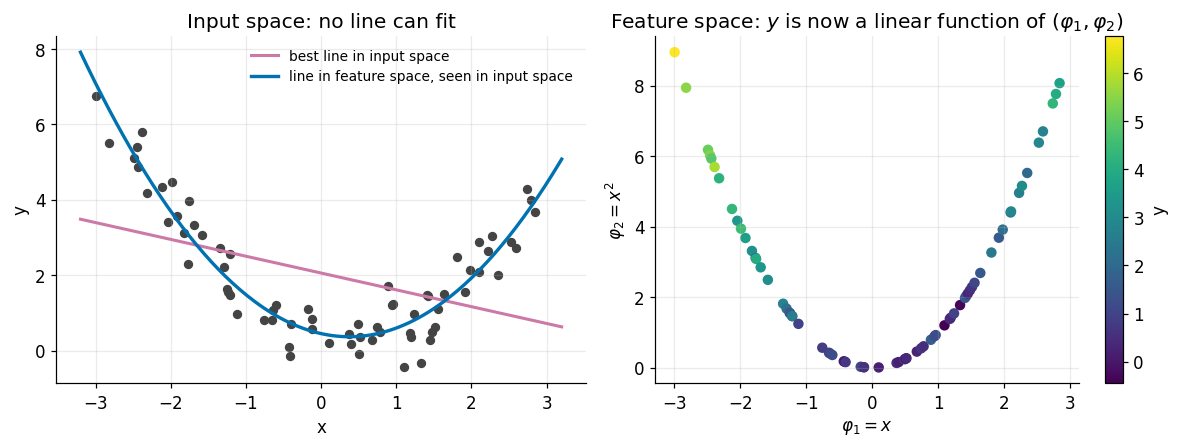

fitted plane:  y = -0.443*x + 0.590*x^2 + 0.451   (true coefficients: -0.5, +0.6, +0.4)


In [9]:
# Explicit feature lift:  x  ->  (x, x^2).  Curved in 1-D, flat in 2-D feature space.
rng = np.random.default_rng(3)
x1  = np.sort(rng.uniform(-3, 3, 70))
y1  = 0.6*x1**2 - 0.5*x1 + 0.4 + 0.5*rng.standard_normal(70)
Phi = np.column_stack([x1, x1**2])                 # the feature map phi(x)
lin = LinearRegression().fit(Phi, y1)              # a *linear* model in feature space

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
xs = np.linspace(-3.2, 3.2, 200)
ax.scatter(x1, y1, s=26, c=C_DATA)
ax.plot(xs, LinearRegression().fit(x1.reshape(-1,1), y1).predict(xs.reshape(-1,1)),
        color=C_BOUND, lw=2, label="best line in input space")
ax.plot(xs, lin.predict(np.column_stack([xs, xs**2])), color=C_FIT, lw=2.2,
        label="line in feature space, seen in input space")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title("Input space: no line can fit")
ax.legend(fontsize=9)

ax = axes[1]
sc = ax.scatter(x1, x1**2, c=y1, cmap="viridis", s=34)
ax.set_xlabel(r"$\varphi_1 = x$"); ax.set_ylabel(r"$\varphi_2 = x^2$")
ax.set_title("Feature space: $y$ is now a linear function of $(\\varphi_1,\\varphi_2)$")
fig.colorbar(sc, ax=ax, label="y")
fig.tight_layout(); plt.show()

print(f"fitted plane:  y = {lin.coef_[0]:.3f}*x + {lin.coef_[1]:.3f}*x^2 + {lin.intercept_:.3f}"
      f"   (true coefficients: -0.5, +0.6, +0.4)")

In [10]:
# The same lift in 3-D -- rotate it to see that the data really is planar in feature space.
try:
    import plotly.graph_objects as go
    g1 = np.linspace(-3.2, 3.2, 30)
    g2 = np.linspace(0, 10.5, 30)
    G1, G2 = np.meshgrid(g1, g2)
    plane = lin.intercept_ + lin.coef_[0]*G1 + lin.coef_[1]*G2

    fig3d = go.Figure([
        go.Surface(x=G1, y=G2, z=plane, opacity=0.55, showscale=False,
                   colorscale="Blues", name="fitted hyperplane"),
        go.Scatter3d(x=x1, y=x1**2, z=y1, mode="markers",
                     marker=dict(size=4, color="#D55E00"), name="data"),
    ])
    fig3d.update_layout(
        title="Lifted space: the data lies on a plane in (x, x², y)",
        scene=dict(xaxis_title="φ₁ = x", yaxis_title="φ₂ = x²", zaxis_title="y"),
        width=760, height=560, margin=dict(l=0, r=0, t=40, b=0))
    fig3d.show()
except ImportError:
    from mpl_toolkits.mplot3d import Axes3D          # noqa: F401
    fig = plt.figure(figsize=(7.5, 5.5)); ax = fig.add_subplot(111, projection="3d")
    g1 = np.linspace(-3.2, 3.2, 30); g2 = np.linspace(0, 10.5, 30)
    G1, G2 = np.meshgrid(g1, g2)
    ax.plot_surface(G1, G2, lin.intercept_ + lin.coef_[0]*G1 + lin.coef_[1]*G2,
                    alpha=0.4, color=C_TUBE)
    ax.scatter(x1, x1**2, y1, c=C_SV, s=20)
    ax.set_xlabel("φ₁ = x"); ax.set_ylabel("φ₂ = x²"); ax.set_zlabel("y")
    plt.show()

In [11]:
def plot_gram_matrices(gamma=0.5, degree=3, coef0=1.0):
    """The Gram matrix IS the model's view of the data. Different kernels, different geometry."""
    Xs = (X - X.mean()) / X.std()
    kernels = {
        "linear": linear_kernel(Xs, Xs),
        f"poly (d={degree})": polynomial_kernel(Xs, Xs, degree=degree, gamma=1.0, coef0=coef0),
        f"RBF γ={gamma:g}": rbf_kernel(Xs, Xs, gamma=gamma),
        "RBF γ=20 (too local)": rbf_kernel(Xs, Xs, gamma=20.0),
        "sigmoid (not PSD)": sigmoid_kernel(Xs, Xs, gamma=0.5, coef0=coef0),
    }
    fig, axes = plt.subplots(1, len(kernels), figsize=(15, 3.3))
    for ax, (name, K) in zip(axes, kernels.items()):
        im = ax.imshow(K, cmap="viridis")
        evmin = np.linalg.eigvalsh((K + K.T)/2).min()
        ax.set_title(f"{name}\nλ$_{{min}}$ = {evmin:+.2f}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        fig.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle("Gram matrices (points sorted by x).  λ$_{min}\\geq 0$ ⇔ PSD ⇔ Mercer-valid",
                 y=1.06, fontsize=11)
    fig.tight_layout(); plt.show()

show(plot_gram_matrices,
     gamma=FloatSlider(value=0.5, min=0.02, max=5.0, step=0.02, description="γ") if HAS_WIDGETS else 0.5,
     degree=IntSlider(value=3, min=1, max=6, description="poly d") if HAS_WIDGETS else 3,
     coef0=FloatSlider(value=1.0, min=0.0, max=3.0, step=0.1, description="r") if HAS_WIDGETS else 1.0)

interactive(children=(FloatSlider(value=0.5, description='γ', max=5.0, min=0.02, step=0.02), IntSlider(value=3…

<function __main__.plot_gram_matrices(gamma=0.5, degree=3, coef0=1.0)>

### 8.5 The single most clarifying picture: SVR as a sum of bumps

For the RBF kernel, $f(x)=\sum_i\beta_i e^{-\gamma(x-x_i)^2}+b$ is literally a **sum of Gaussian
bumps, one centred on each support vector**, with signed heights $\beta_i$ and common width
$\sigma=1/\sqrt{2\gamma}$. Nothing more.

The next cell draws the individual bumps and their sum. Once you see this, three things stop being
mysterious:

* **$\gamma$ sets bump width.** Large $\gamma$ ⇒ narrow spikes that only reach their own training
  point ⇒ the fit becomes a row of needles on a flat background (and far from any SV, $f(x)\to b$).
  Small $\gamma$ ⇒ wide, overlapping bumps ⇒ an almost linear, over-smoothed fit.
* **Why extrapolation fails.** Far outside the data, every kernel value decays to 0 and the
  prediction reverts to the constant $b$. **An RBF-SVR cannot extrapolate a trend** — a crucial
  caveat for time-series work.
* **Why sparsity matters for speed.** Fewer bumps = fewer kernel evaluations per prediction.

In [12]:
def plot_rbf_bumps(gamma=0.5, C=10.0, eps=0.2, show_components=True):
    m = SVR(kernel="rbf", C=C, epsilon=eps, gamma=gamma).fit(X, y)
    sv, beta, b = X[m.support_].ravel(), m.dual_coef_.ravel(), m.intercept_[0]
    xs = np.linspace(-5.5, 5.5, 600)                 # deliberately wider than the data
    comps = beta[:, None] * np.exp(-gamma * (xs[None, :] - sv[:, None])**2)

    fig, axes = plt.subplots(2, 1, figsize=(9.5, 7.0), sharex=True,
                             gridspec_kw={"height_ratios": [1.0, 1.4]})
    ax = axes[0]
    if show_components:
        for c in comps:
            ax.plot(xs, c, lw=0.9, alpha=0.55,
                    color=(C_SV if c[np.argmax(np.abs(c))] > 0 else C_BOUND))
    ax.axhline(0, color=C_DATA, lw=0.8)
    ax.scatter(sv, np.zeros_like(sv), marker="|", s=120, color=C_DATA)
    ax.set_ylabel(r"$\beta_i\,k(x_i,x)$")
    ax.set_title(rf"{len(sv)} individual kernel bumps (width $\sigma=1/\sqrt{{2\gamma}}$ = "
                 rf"{1/np.sqrt(2*gamma):.2f}),  ticks = support vectors")

    ax = axes[1]
    ax.axvspan(X.min(), X.max(), color="#000000", alpha=0.04)
    ax.plot(xs, comps.sum(axis=0) + b, color=C_FIT, lw=2.4, label=r"$f(x)=\sum_i\beta_ik(x_i,x)+b$")
    ax.axhline(b, color=C_BOUND, ls="--", lw=1.4, label=f"intercept b = {b:.2f}")
    ax.scatter(X, y, s=26, c=C_DATA, zorder=3, label="training data")
    ax.annotate("outside the data the bumps die\nand $f(x)\\to b$: no extrapolation",
                xy=(4.6, b), xytext=(2.4, b + 1.1), fontsize=9, color=C_BOUND,
                arrowprops=dict(arrowstyle="->", color=C_BOUND))
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper left", fontsize=9)
    fig.tight_layout(); plt.show()

show(plot_rbf_bumps,
     gamma=FloatSlider(value=0.5, min=0.02, max=8.0, step=0.02, description="γ") if HAS_WIDGETS else 0.5,
     C=FloatSlider(value=10.0, min=0.1, max=100.0, step=0.1, description="C") if HAS_WIDGETS else 10.0,
     eps=FloatSlider(value=0.2, min=0.0, max=1.2, step=0.02, description="ε") if HAS_WIDGETS else 0.2,
     show_components=Checkbox(value=True, description="show bumps") if HAS_WIDGETS else True)

interactive(children=(FloatSlider(value=0.5, description='γ', max=8.0, min=0.02, step=0.02), FloatSlider(value…

<function __main__.plot_rbf_bumps(gamma=0.5, C=10.0, eps=0.2, show_components=True)>

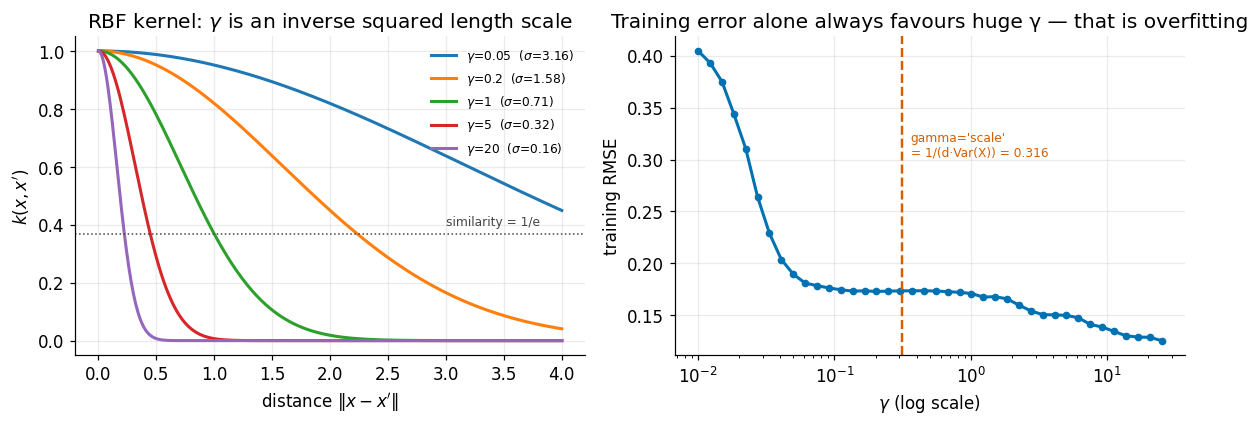

In [13]:
def plot_gamma_geometry():
    """gamma in distance units: k(x,x') = exp(-gamma d^2).  Where does similarity die?"""
    d = np.linspace(0, 4, 400)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))

    ax = axes[0]
    for g in [0.05, 0.2, 1.0, 5.0, 20.0]:
        ax.plot(d, np.exp(-g*d**2), lw=2, label=rf"$\gamma$={g:g}  ($\sigma$={1/np.sqrt(2*g):.2f})")
    ax.axhline(np.exp(-1), color=C_DATA, ls=":", lw=1)
    ax.text(3.0, np.exp(-1)+0.03, "similarity = 1/e", fontsize=8, color=C_DATA)
    ax.set_xlabel(r"distance $\|x-x'\|$"); ax.set_ylabel(r"$k(x,x')$")
    ax.set_title(r"RBF kernel: $\gamma$ is an inverse squared length scale"); ax.legend(fontsize=8)

    # how sklearn's default gamma='scale' is computed, and why it adapts to the data
    ax = axes[1]
    gammas = np.logspace(-2, 1.4, 40)
    n_sv, rmse = [], []
    for g in gammas:
        m = SVR(kernel="rbf", C=10.0, epsilon=0.1, gamma=g).fit(X, y)
        n_sv.append(len(m.support_)); rmse.append(np.sqrt(np.mean((y - m.predict(X))**2)))
    ax.semilogx(gammas, rmse, "o-", color=C_FIT, lw=2, ms=4)
    g_scale = 1.0 / (X.shape[1] * X.var())
    ax.axvline(g_scale, color=C_SV, ls="--", lw=1.6)
    ax.text(g_scale*1.15, max(rmse)*0.75, f"gamma='scale'\n= 1/(d·Var(X)) = {g_scale:.3f}",
            fontsize=8, color=C_SV)
    ax.set_xlabel(r"$\gamma$ (log scale)"); ax.set_ylabel("training RMSE")
    ax.set_title("Training error alone always favours huge γ — that is overfitting")
    fig.tight_layout(); plt.show()

plot_gamma_geometry()

---
## 9. The three dials, side by side

| Dial | Lives in | Controls | Too small | Too large |
|---|---|---|---|---|
| $C$ | objective | price of tube violations | underfit: $f\to$ flat/constant | overfit: interpolates noise; slow convergence |
| $\varepsilon$ | loss | tube half-width (units of $y$!) | dense model, fits noise, many SVs | coarse step-like fit, few SVs, biased |
| $\gamma$ (RBF) | kernel | similarity length scale | over-smooth, near-linear | spiky, memorises, reverts to $b$ between points |

They **interact** — $C$ and $\gamma$ especially, which is why they are tuned on a 2-D grid
(logarithmic, e.g. $C\in\{10^{-1}\dots10^{3}\}$, $\gamma\in\{10^{-4}\dots10^{1}\}$) and never one at
a time. The classic guidance (Hsu, Chang & Lin's libsvm practical guide) is: scale the data, then
coarse log grid, then a fine grid around the winner.

The explorer below reports held-out RMSE as well as training RMSE. Watch the gap open as you push
$C$ and $\gamma$ up: that gap **is** overfitting, made visible.

In [14]:
X_all, y_all = make_wave(n=120, noise=0.25, seed=7)
_rng   = np.random.default_rng(11)
_perm  = _rng.permutation(len(y_all))
_tr, _te = _perm[:80], _perm[80:]
Xtr, ytr, Xte, yte = X_all[_tr], y_all[_tr], X_all[_te], y_all[_te]

def explore_svr(C=10.0, eps=0.2, gamma=0.5, kernel="rbf"):
    m = SVR(kernel=kernel, C=C, epsilon=eps, gamma=gamma).fit(Xtr, ytr)
    yg = m.predict(X_grid)
    rmse_tr = np.sqrt(np.mean((ytr - m.predict(Xtr))**2))
    rmse_te = np.sqrt(np.mean((yte - m.predict(Xte))**2))

    fig, ax = plt.subplots(figsize=(9.5, 5.0))
    ax.fill_between(X_grid.ravel(), yg - eps, yg + eps, color=C_TUBE, alpha=0.28)
    ax.plot(X_grid, yg, color=C_FIT, lw=2.2, label="$f(x)$")
    ax.scatter(Xtr, ytr, s=26, c=C_DATA, zorder=3, label="train")
    ax.scatter(Xte, yte, s=34, facecolors="none", edgecolors=C_IN, lw=1.5, zorder=3, label="test")
    ax.scatter(Xtr[m.support_], ytr[m.support_], s=90, facecolors="none",
               edgecolors=C_SV, lw=1.2, zorder=2, label=f"SVs ({len(m.support_)}/{len(ytr)})")
    ax.set_ylim(y_all.min() - 0.8, y_all.max() + 0.8)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper left", fontsize=9, ncol=2)
    ax.set_title(f"C={C:g}  ε={eps:g}  γ={gamma:g}   |   "
                 f"train RMSE {rmse_tr:.3f}   test RMSE {rmse_te:.3f}   "
                 f"(gap {rmse_te - rmse_tr:+.3f})")
    fig.tight_layout(); plt.show()

show(explore_svr,
     C=FloatSlider(value=10.0, min=0.01, max=300.0, step=0.5, description="C") if HAS_WIDGETS else 10.0,
     eps=FloatSlider(value=0.2, min=0.0, max=1.5, step=0.02, description="ε") if HAS_WIDGETS else 0.2,
     gamma=FloatSlider(value=0.5, min=0.01, max=30.0, step=0.05, description="γ") if HAS_WIDGETS else 0.5,
     kernel=Dropdown(options=["rbf", "linear", "poly", "sigmoid"], value="rbf",
                     description="kernel") if HAS_WIDGETS else "rbf")

interactive(children=(FloatSlider(value=10.0, description='C', max=300.0, min=0.01, step=0.5), FloatSlider(val…

<function __main__.explore_svr(C=10.0, eps=0.2, gamma=0.5, kernel='rbf')>

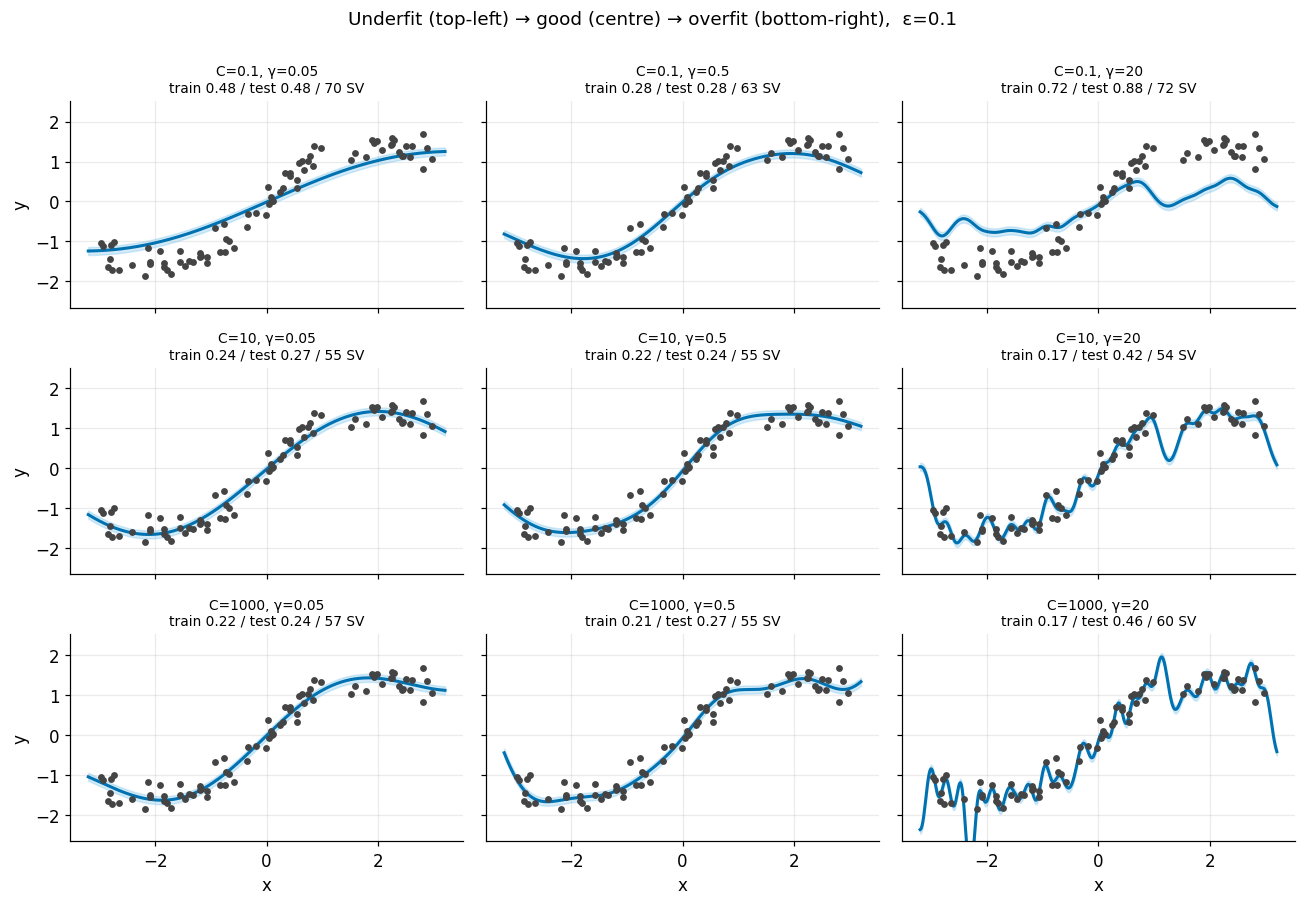

In [15]:
def hyperparameter_grid(eps=0.1):
    """A static C x gamma panel: the global picture the sliders show one point at a time."""
    Cs     = [0.1, 10.0, 1000.0]
    gammas = [0.05, 0.5, 20.0]
    fig, axes = plt.subplots(len(Cs), len(gammas), figsize=(12, 8.2), sharex=True, sharey=True)
    for i, Cv in enumerate(Cs):
        for j, gv in enumerate(gammas):
            ax = axes[i, j]
            m = SVR(kernel="rbf", C=Cv, epsilon=eps, gamma=gv).fit(Xtr, ytr)
            yg = m.predict(X_grid)
            ax.fill_between(X_grid.ravel(), yg - eps, yg + eps, color=C_TUBE, alpha=0.25)
            ax.plot(X_grid, yg, color=C_FIT, lw=2)
            ax.scatter(Xtr, ytr, s=12, c=C_DATA, zorder=3)
            tr = np.sqrt(np.mean((ytr - m.predict(Xtr))**2))
            te = np.sqrt(np.mean((yte - m.predict(Xte))**2))
            ax.set_title(f"C={Cv:g}, γ={gv:g}\ntrain {tr:.2f} / test {te:.2f} / {len(m.support_)} SV",
                         fontsize=9)
            ax.set_ylim(y_all.min()-0.8, y_all.max()+0.8)
    for ax in axes[-1, :]: ax.set_xlabel("x")
    for ax in axes[:, 0]:  ax.set_ylabel("y")
    fig.suptitle(f"Underfit (top-left) → good (centre) → overfit (bottom-right),  ε={eps:g}",
                 y=1.00, fontsize=12)
    fig.tight_layout(); plt.show()

hyperparameter_grid(eps=0.1)

---
## 10. $\nu$-SVR: letting the data choose $\varepsilon$

Choosing $\varepsilon$ requires knowing the noise level in $y$ — which you usually don't. Schölkopf,
Smola, Williamson & Bartlett's **$\nu$-SVR** replaces it with a dimensionless $\nu\in(0,1]$ and makes
$\varepsilon$ an *optimisation variable*:

$$
\min_{w,b,\varepsilon\ge0,\xi,\xi^{*}}\;
\tfrac12\lVert w\rVert^{2}
+C\Bigl(\nu\,\varepsilon+\tfrac1n\sum_i(\xi_i+\xi_i^{*})\Bigr)
\quad\text{s.t. the same tube constraints.}
$$

The term $C\nu\varepsilon$ charges rent for a wide tube, so the optimiser shrinks $\varepsilon$ until
the rent balances the violations it prevents. The dual is the $\varepsilon$-SVR dual with the
$\varepsilon$-term removed and an extra constraint:

$$
\max_{\alpha,\alpha^{*}}\;-\tfrac12\sum_{i,j}\beta_i\beta_j k(x_i,x_j)+\sum_i y_i\beta_i
\quad\text{s.t.}\quad \sum_i\beta_i=0,\;\;
\sum_i(\alpha_i+\alpha_i^{*})\le C\nu,\;\;
\alpha_i^{(*)}\in\Bigl[0,\tfrac{C}{n}\Bigr].
$$

### The $\nu$-property (the reason anyone uses it)

> $\nu$ is an **upper bound on the fraction of points lying outside the tube** ("errors") and a
> **lower bound on the fraction of support vectors**. Asymptotically, both fractions converge to $\nu$.

$$
\frac{\#\{\text{points outside the tube}\}}{n}\;\le\;\nu\;\le\;\frac{\#\mathrm{SV}}{n}
$$

So $\nu=0.3$ means: *"about 30 % of my data may stick out of the tube."* That is a statement you can
reason about directly, which $\varepsilon = 0.17$ is not. $\varepsilon$-SVR and $\nu$-SVR produce the
**same family of solutions** — for every $\nu$ there is an $\varepsilon$ giving the identical fit; only
the parameterisation differs. Use $\nu$-SVR when you can guess an outlier fraction, $\varepsilon$-SVR
when you know the measurement precision of $y$.

In the plot below $\varepsilon$ is recovered empirically from the margin SVs (scikit-learn does not
expose the fitted value), so the two curves bracket $\nu$ to within that estimation error.

In [16]:
def nu_property(C=10.0, gamma=0.5, n=160):
    Xn, yn = make_wave(n=n, noise=0.25, seed=5)
    nus = np.linspace(0.05, 0.95, 19)
    frac_out, frac_sv, eps_fit = [], [], []
    for nu in nus:
        m = NuSVR(nu=nu, C=C, gamma=gamma).fit(Xn, yn)
        r = yn - m.predict(Xn)
        beta = np.zeros(n); beta[m.support_] = m.dual_coef_.ravel()
        margin = (np.abs(beta) > 1e-8) & (np.abs(beta) < C - 1e-6)   # on the tube wall
        e_hat = np.median(np.abs(r[margin])) if margin.any() else 0.0
        eps_fit.append(e_hat)
        frac_out.append(np.mean(np.abs(r) > e_hat + 1e-9))
        frac_sv.append(len(m.support_) / n)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    ax = axes[0]
    ax.plot(nus, nus, color=C_DATA, ls=":", lw=1.5, label=r"$y=\nu$")
    ax.plot(nus, frac_out, "o-", color=C_BOUND, lw=2, ms=4, label="fraction outside tube  ≤ ν")
    ax.plot(nus, frac_sv,  "s-", color=C_SV,    lw=2, ms=4, label="fraction of SVs  ≥ ν")
    ax.fill_between(nus, frac_out, frac_sv, color=C_TUBE, alpha=0.25)
    ax.set_xlabel(r"$\nu$"); ax.set_ylabel("fraction of training points")
    ax.set_title("The ν-property: ν is squeezed between the two"); ax.legend(fontsize=9)

    ax = axes[1]
    ax.plot(nus, eps_fit, "o-", color=C_FIT, lw=2, ms=4)
    ax.set_xlabel(r"$\nu$"); ax.set_ylabel(r"fitted $\varepsilon$ (recovered from margin SVs)")
    ax.set_title(r"Large $\nu$ ⇒ expensive tube ⇒ the optimiser shrinks $\varepsilon$")
    fig.tight_layout(); plt.show()

show(nu_property,
     C=FloatSlider(value=10.0, min=0.5, max=100.0, step=0.5, description="C") if HAS_WIDGETS else 10.0,
     gamma=FloatSlider(value=0.5, min=0.02, max=5.0, step=0.02, description="γ") if HAS_WIDGETS else 0.5)

interactive(children=(FloatSlider(value=10.0, description='C', min=0.5, step=0.5), FloatSlider(value=0.5, desc…

<function __main__.nu_property(C=10.0, gamma=0.5, n=160)>

---
## 11. Why feature scaling is not optional (it is part of the theory)

This is the number-one practical failure of SVR, and it follows directly from the mathematics:

1. **The RBF kernel sees only Euclidean distance**, $\lVert x-x'\rVert^2=\sum_j (x_j-x'_j)^2$. A
   feature measured in µg/kg (values $\sim10^3$) and one measured as a pH (values $\sim 7$) do not
   contribute comparably — the large-scale feature swamps the sum and the small one is invisible to
   the kernel. A *single* $\gamma$ is shared by all features, so they must share a scale.
2. **$\varepsilon$ is in the units of $y$.** With $y$ in mg/kg and $\varepsilon=0.1$, the tube is
   0.1 mg/kg wide — possibly far narrower than the noise, which makes nearly every point a support
   vector and destroys sparsity. Standardise $y$ (or set $\varepsilon$ as a fraction of $\mathrm{sd}(y)$).
3. **$C$ trades against the scale of $y$ too**, since it multiplies a sum of residual-like terms.

**Rule:** always wrap SVR in a `Pipeline` with `StandardScaler` (fit on the training fold only —
never on the whole dataset, which leaks test information), and standardise or
`TransformedTargetRegressor`-wrap $y$.

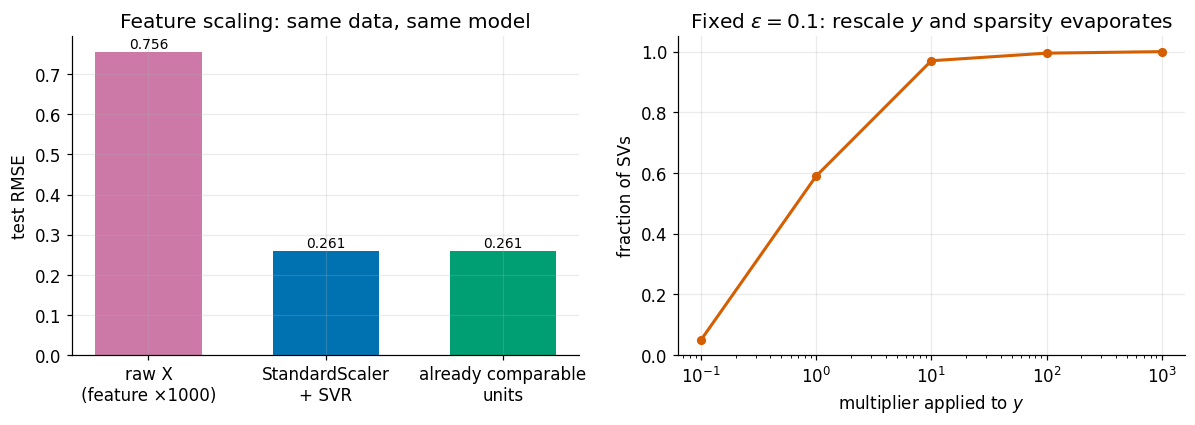

test RMSE   raw=0.756   scaled=0.261   comparable-units=0.261


In [17]:
def scaling_demo():
    """Two features that matter equally -- but one is recorded in 'bigger' units."""
    rng = np.random.default_rng(1)
    n = 300
    Z = rng.standard_normal((n, 2))
    yv = np.sin(Z[:, 0]) + 0.8*Z[:, 1] + 0.15*rng.standard_normal(n)
    Xbad = Z.copy(); Xbad[:, 1] *= 1000.0            # same information, different unit
    tr, te = slice(0, 200), slice(200, None)

    def rmse(model, Xd, scale_y=1.0):
        model.fit(Xd[tr], yv[tr]*scale_y)
        return np.sqrt(np.mean((yv[te]*scale_y - model.predict(Xd[te]))**2)) / scale_y

    raw    = rmse(SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale"), Xbad)
    scaled = rmse(make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.1)), Xbad)
    ideal  = rmse(make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10, epsilon=0.1)), Z)

    # effect of the SCALE OF y on sparsity, at fixed epsilon
    scales = [0.1, 1, 10, 100, 1000]
    nsv = []
    for s in scales:
        m = SVR(kernel="rbf", C=10, epsilon=0.1, gamma="scale").fit(Z[tr], yv[tr]*s)
        nsv.append(len(m.support_) / 200)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
    ax = axes[0]
    bars = ax.bar(["raw X\n(feature ×1000)", "StandardScaler\n+ SVR", "already comparable\nunits"],
                  [raw, scaled, ideal], color=[C_BOUND, C_FIT, C_IN], width=0.6)
    ax.bar_label(bars, fmt="%.3f", fontsize=9)
    ax.set_ylabel("test RMSE"); ax.set_title("Feature scaling: same data, same model")

    ax = axes[1]
    ax.semilogx(scales, nsv, "o-", color=C_SV, lw=2, ms=5)
    ax.set_xlabel("multiplier applied to $y$"); ax.set_ylabel("fraction of SVs")
    ax.set_ylim(0, 1.05)
    ax.set_title(r"Fixed $\varepsilon=0.1$: rescale $y$ and sparsity evaporates")
    fig.tight_layout(); plt.show()
    print(f"test RMSE   raw={raw:.3f}   scaled={scaled:.3f}   comparable-units={ideal:.3f}")

scaling_demo()

---
## 12. Computational complexity — what the dual costs

The dual has $2n$ variables and a dense $n\times n$ Gram matrix, so:

| Quantity | Cost | Consequence |
|---|---|---|
| Training (libsvm SMO) | between $O(n^{2}d)$ and $O(n^{3}d)$ | ~fine to $n\approx10^4$; painful beyond |
| Kernel cache | $O(n^{2})$ memory if cached in full | `cache_size=1000` (MB) is a cheap speed-up |
| Prediction | $O(n_{\mathrm{SV}}\,d)$ per point | sparsity directly = inference speed |

`SVR` solves the dual with **SMO** (sequential minimal optimisation): repeatedly pick the pair of
multipliers that most violates the KKT conditions, solve that 2-variable sub-problem in closed form
(the equality constraint $\sum\beta_i=0$ forces you to move two at a time), repeat. Memory stays
$O(n)$ apart from the cache.

Escape routes when $n$ is large — the practical ones, in order:
1. `LinearSVR` (liblinear, solves the **primal**, $O(nd)$) when a linear kernel suffices;
2. **Nyström** or **random Fourier features** (`sklearn.kernel_approximation`) to approximate the RBF
   feature map explicitly, then `LinearSVR`/`SGDRegressor` on top — near-kernel accuracy at linear cost;
3. raise `tol`, raise `cache_size`, subsample.

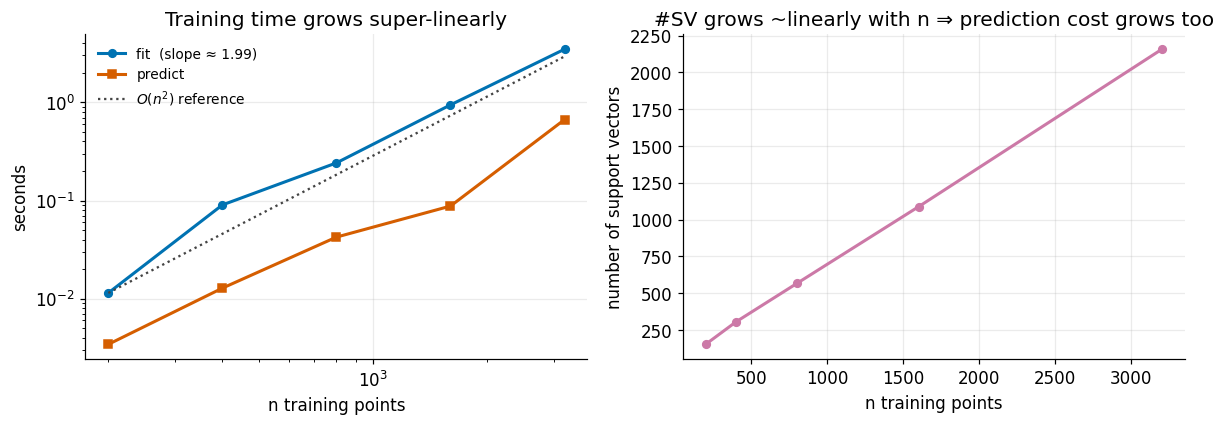

In [18]:
def complexity_curve(sizes=(200, 400, 800, 1600, 3200)):
    import time
    rng = np.random.default_rng(0)
    fit_t, pred_t, nsv = [], [], []
    for n in sizes:
        Xb = rng.standard_normal((n, 8))
        yb = np.sin(Xb[:, 0]) + 0.5*Xb[:, 1] + 0.2*rng.standard_normal(n)
        m = SVR(kernel="rbf", C=10, epsilon=0.1, cache_size=500)
        t0 = time.perf_counter(); m.fit(Xb, yb); fit_t.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); m.predict(Xb); pred_t.append(time.perf_counter() - t0)
        nsv.append(len(m.support_))

    sizes = np.asarray(sizes, float)
    slope = np.polyfit(np.log(sizes), np.log(fit_t), 1)[0]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
    ax = axes[0]
    ax.loglog(sizes, fit_t, "o-", color=C_FIT, lw=2, ms=5, label=f"fit  (slope ≈ {slope:.2f})")
    ax.loglog(sizes, pred_t, "s-", color=C_SV, lw=2, ms=5, label="predict")
    ax.loglog(sizes, fit_t[0]*(sizes/sizes[0])**2, ":", color=C_DATA, label=r"$O(n^2)$ reference")
    ax.set_xlabel("n training points"); ax.set_ylabel("seconds"); ax.legend(fontsize=9)
    ax.set_title("Training time grows super-linearly")

    ax = axes[1]
    ax.plot(sizes, nsv, "o-", color=C_BOUND, lw=2, ms=5)
    ax.set_xlabel("n training points"); ax.set_ylabel("number of support vectors")
    ax.set_title("#SV grows ~linearly with n ⇒ prediction cost grows too")
    fig.tight_layout(); plt.show()

complexity_curve()

---
## 13. Where SVR sits among its relatives

Every method in this family minimises **loss + regularisation**; they differ only in which loss and
which hypothesis space.

| Method | Loss | Regulariser | Space | Sparse? | Uncertainty? | Solution |
|---|---|---|---|---|---|---|
| OLS | $r^2$ | none | linear | no | via Gaussian theory | closed form |
| Ridge | $r^2$ | $\lambda\lVert w\rVert^2$ | linear | no | — | closed form |
| **Kernel ridge (KRR)** | $r^2$ | $\lambda\lVert w\rVert^2_{\mathcal H}$ | RKHS | **no** (all $n$ points) | — | closed form, $O(n^3)$ |
| **SVR** | $(\lvert r\rvert-\varepsilon)_+$ | $\tfrac12\lVert w\rVert^2$ | RKHS | **yes** | no | convex QP |
| Gaussian process | $r^2$ (neg. log-lik.) | GP prior | RKHS | no | **full posterior** | closed form, $O(n^3)$ |

**KRR and SVR use the same kernel and the same $\ell_2$ penalty — the only difference is the loss.**
That one change buys sparsity and robustness and costs you a closed-form solution. If you want
uncertainty bands, a GP is the natural choice; SVR gives a point prediction only (for intervals,
wrap it in conformal prediction or quantile bootstrapping).

### The representer theorem — why kernels work at all

For any loss $L$ and any strictly increasing $\Omega$, the minimiser of
$\sum_i L(y_i,f(x_i))+\Omega(\lVert f\rVert_{\mathcal H})$ over an RKHS $\mathcal H$ has the form

$$
f^{*}(x)=\sum_{i=1}^{n}c_i\,k(x_i,x).
$$

An infinite-dimensional search collapses to $n$ coefficients. SVR's extra contribution is that its
loss makes most of those $c_i$ **exactly zero**.

In [19]:
def compare_family(alpha_krr=0.1, C=10.0, eps=0.3, gamma=0.5):
    from sklearn.gaussian_process import GaussianProcessRegressor
    from sklearn.gaussian_process.kernels import RBF as RBFk, WhiteKernel, ConstantKernel

    Xo, yo = make_wave(n=70, noise=0.2, seed=2, outliers=3)      # 3 gross outliers

    svr = SVR(kernel="rbf", C=C, epsilon=eps, gamma=gamma).fit(Xo, yo)
    krr = KernelRidge(kernel="rbf", alpha=alpha_krr, gamma=gamma).fit(Xo, yo)
    gp  = GaussianProcessRegressor(ConstantKernel(1.0) * RBFk(1.0) + WhiteKernel(0.1),
                                   normalize_y=True, random_state=0).fit(Xo, yo)
    mu, sd = gp.predict(X_grid, return_std=True)

    fig, ax = plt.subplots(figsize=(9.8, 5.2))
    ax.fill_between(X_grid.ravel(), mu - 2*sd, mu + 2*sd, color=C_IN, alpha=0.15,
                    label="GP ±2σ (uncertainty SVR cannot give)")
    ax.plot(X_grid, krr.predict(X_grid), lw=2, color=C_BOUND,
            label=f"kernel ridge — dense, uses all {len(yo)} points")
    ax.plot(X_grid, mu, lw=2, color=C_IN, ls="--", label="GP posterior mean")
    ax.plot(X_grid, svr.predict(X_grid), lw=2.6, color=C_FIT,
            label=f"SVR — sparse, {len(svr.support_)} SVs")
    ax.scatter(Xo, yo, s=26, c=C_DATA, zorder=3, label="data (3 outliers injected)")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(loc="upper left", fontsize=9)
    ax.set_title("Same kernel, three losses: squared (KRR, GP) vs ε-insensitive (SVR)")
    fig.tight_layout(); plt.show()

    print(f"SVR uses {len(svr.support_)}/{len(yo)} points; KRR and GP use all {len(yo)}.")
    print("Notice how the squared-loss curves bend toward the outliers and SVR largely ignores them.")

show(compare_family,
     alpha_krr=FloatSlider(value=0.1, min=0.001, max=2.0, step=0.01, description="α (KRR)") if HAS_WIDGETS else 0.1,
     C=FloatSlider(value=10.0, min=0.1, max=100.0, step=0.1, description="C") if HAS_WIDGETS else 10.0,
     eps=FloatSlider(value=0.3, min=0.0, max=1.5, step=0.02, description="ε") if HAS_WIDGETS else 0.3,
     gamma=FloatSlider(value=0.5, min=0.02, max=5.0, step=0.02, description="γ") if HAS_WIDGETS else 0.5)

interactive(children=(FloatSlider(value=0.1, description='α (KRR)', max=2.0, min=0.001, step=0.01), FloatSlide…

<function __main__.compare_family(alpha_krr=0.1, C=10.0, eps=0.3, gamma=0.5)>

---
## 14. Cheat sheet

### The method in six lines
1. Choose a tube half-width $\varepsilon$: errors inside it are free.
2. Among functions that keep the data (mostly) in the tube, pick the flattest: minimise $\tfrac12\lVert w\rVert^2$.
3. Allow violations, priced at $C$ each: $\min\ \tfrac12\lVert w\rVert^2 + C\sum(\xi_i+\xi_i^*)$.
4. Take the dual ⇒ the data appears only as inner products ⇒ replace them with a kernel $k$.
5. KKT ⇒ interior points get $\beta_i=0$; the rest are support vectors, capped at $\lvert\beta_i\rvert\le C$.
6. Predict with $f(x)=\sum_{i\in\mathrm{SV}}\beta_i k(x_i,x)+b$.

### Symbol table

| Symbol | Meaning | sklearn |
|---|---|---|
| $\varepsilon$ | tube half-width, units of $y$ | `epsilon` |
| $C$ | violation price / multiplier ceiling | `C` |
| $\gamma$ | RBF inverse squared length scale | `gamma` |
| $\beta_i=\alpha_i-\alpha_i^{*}$ | dual coefficients | `dual_coef_` |
| support vectors | points with $\beta_i\ne0$ | `support_vectors_`, `support_` |
| $b$ | intercept | `intercept_` |
| $\nu$ | error/SV fraction (ν-SVR) | `NuSVR(nu=...)` |

### Ten misconceptions, corrected
1. *"The support vectors are the points closest to the curve."* — The opposite: they are the points **on or outside** the tube wall. Interior points are discarded.
2. *"$\varepsilon$ is a tolerance on accuracy."* — It is a tolerance on the **training residual**; test error is typically larger than $\varepsilon$.
3. *"Bigger $C$ is more regularisation."* — Backwards. $C$ multiplies the *loss*; large $C$ means **less** regularisation. (In ridge, $\alpha$ multiplies the penalty — opposite convention.)
4. *"SVR computes $\varphi(x)$."* — Never. Only $k(x_i,x_j)$ is ever evaluated.
5. *"Any similarity function works as a kernel."* — It must be symmetric PSD (Mercer); otherwise convexity is lost.
6. *"Scaling is a preprocessing nicety."* — It is part of the model definition: $\gamma$ is shared across features and $\varepsilon$ lives in $y$-units.
7. *"RBF-SVR can extrapolate a trend."* — It cannot. Beyond the data all kernels decay and $f(x)\to b$. Use a linear kernel, or detrend first.
8. *"The solution might be a local optimum."* — It is a convex QP: the optimum is global and unique (given fixed hyper-parameters).
9. *"SVR gives confidence intervals."* — It gives a point prediction. Use conformal prediction or a GP for intervals.
10. *"More support vectors means a better fit."* — It means a more complex, slower model — usually a sign that $\varepsilon$ is too small or $C$/$\gamma$ too large.

### Primary sources
* Vapnik, *The Nature of Statistical Learning Theory*, Springer, 1995.
* Smola & Schölkopf, "A tutorial on support vector regression," *Statistics and Computing* **14**, 199–222, 2004 — the derivation in §5 follows this paper's notation.
* Schölkopf, Smola, Williamson & Bartlett, "New support vector algorithms," *Neural Computation* **12**, 1207–1245, 2000 — the $\nu$ formulation and its property.
* Hsu, Chang & Lin, "A practical guide to support vector classification," NTU, 2003 — the scale-then-log-grid recipe.
* Chang & Lin, "LIBSVM: a library for support vector machines," *ACM TIST* **2**, 27, 2011 — the SMO solver behind `sklearn.svm.SVR`.

---
### Part 2 (applied) would cover
pipelines and leak-free cross-validation · `GridSearchCV` / `RandomizedSearchCV` / Bayesian search ·
`LinearSVR` and Nyström approximations for large $n$ · multi-output SVR · lag-feature construction
and walk-forward validation for **time series** · conformal prediction intervals · permutation
importance and partial-dependence for interpreting a kernel model · benchmarking against random
forests / gradient boosting / LSTM. Ask and I will build it on your own dataset.